# Trabajo Practico 2 - Vision por Computadora 1

**Alumnos:** Juan Pablo Castellino - Walter Gabriel Sotelo - Esteban Leonardo Torres Martin

---

### Enunciado

**Objetivo:
Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las
cámaras digitales modernas. El video a procesar será: “focus_video.mov”.


1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image
Sharpness Measure for Blurred Images in Frequency Domain“ y realizar dos experimentos:


    1. Medición sobre todo el frame.
    
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

Para cada experimento se debe presentar :

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la
región de máximo enfoque.

1. Medicion de foco en toda la imagen

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera
automática.

Puntos extra: Aplicar unsharp masking para expandir la zona de enfoque y devolver.

In [77]:
##Se cargan las librerías necesarias
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

def buscar_carpeta(nombre="videos", niveles=4):
    """Busca una carpeta desde el directorio actual hacia arriba."""
    base = Path.cwd().resolve()
    for carpeta in [base] + list(base.parents)[:niveles]:
        candidata = carpeta / nombre
        if candidata.is_dir():
            return candidata
    raise FileNotFoundError(f"No se encontro la carpeta {nombre!r} desde {base}")

Una imágen enfocada generalmente se caracteriza por transiciónes de intensidad bien definidas, lo cual en el dominio espectral se traduce en "componentes de alta frecuencia". Como se vio en la teórica, el desenfoque funciona algo así como un filtro pasa bajos (de hecho eso es lo que hace el filtro de desenfoque Gaussiano).

Para obtener la métrica en cuestión, el paper realiza los siguientes pasos:

*   1 Calcula la FFT de la imágen y hace el fftshift para que al graficar, la frecuencia 0, o componente de DC quede en el centro de la matriz

*   2 Calcula la magnitud de cada componente de frecuencia (que es equivalente a la raíz cuadrada de la energía aportada por esa frecuencia)

*   3 Encuentra el valor máximo del array de magnitudes calculadas en el paso 2

*   4 Define un umbral correspondiente a un milésimo de la magnitud pico, o sea -60 dB del pico de magnitud de la FFT

*   5 Recorre el array de magnitudes y cuenta cuantas componentes de frecuencia superan el umbral

*   6 Calcula la métrica como la cantidad de componentes contadas en 5 normalizadas por el tamaño de la imágen. En términos matemáticos, ésto es dividir el n{umero calculado en 5 por el producto del ancho de la imágen por el alto (en píxeles). A mayor valor de la métrica, mas nítida es la imágen

En resumen, el método define como componentes de frecuencia significativas a aquellas que están por sobre -60 dBmax, luego calcula la proporción de componentes significativas que contiene la imágen y se establece el criterio de que el nivel de enfoque es proporcional a esta proporción.

In [78]:
def calc_metrica_enfoque(imagen, divisor_umbral=1000.0):

    if imagen is None:
        raise ValueError("La imagen recibida es None.")

    if divisor_umbral <= 0:
        raise ValueError(
            "divisor_umbral debe ser mayor que cero."
        )

    # Procesamiento básico: convertir a escala de grises
    frame_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    # Conversión a punto flotante
    gris_float = frame_gris.astype(np.float32)

    # Paso 1: transformada de Fourier y fftshift para pasar la baja frecuencia al centro
    fft = np.fft.fft2(gris_float)
    fft_centrada = np.fft.fftshift(fft)

    # Paso 2: magnitud absoluta de la FFT centrada
    magnitud = np.abs(fft_centrada)

    # Paso 3: máximo de la magnitud espectral
    maximo = float(np.max(magnitud))

    # Paso 4: umbral especificado por el paper (-60 dBmax es el default)
    umbral = maximo / divisor_umbral

    # Paso 5: Coeficientes mayores que el umbral
    mascara = magnitud > umbral
    cantidad_superiores = int(np.count_nonzero(mascara))

    # Paso 6: Cálculo de métrica
    cantidad_total = frame_gris.size
    fm = cantidad_superiores / cantidad_total

    # Solamente para visualizar el espectro.
    # Esta escala logarítmica NO se usa para calcular FM.
    espectro_log = np.log1p(magnitud)

    return float(fm)

En primer lugar corremos el algoritmo para el frame completo.

Cargando video de la carpeta: videos/focus_video.mov
Cantidad de frames: 171
Resolución: 640 x 360
FM máximo: 0.028624131944444443
Umbral (90%): 0.02576171875
Frames enfocados:
[79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115]


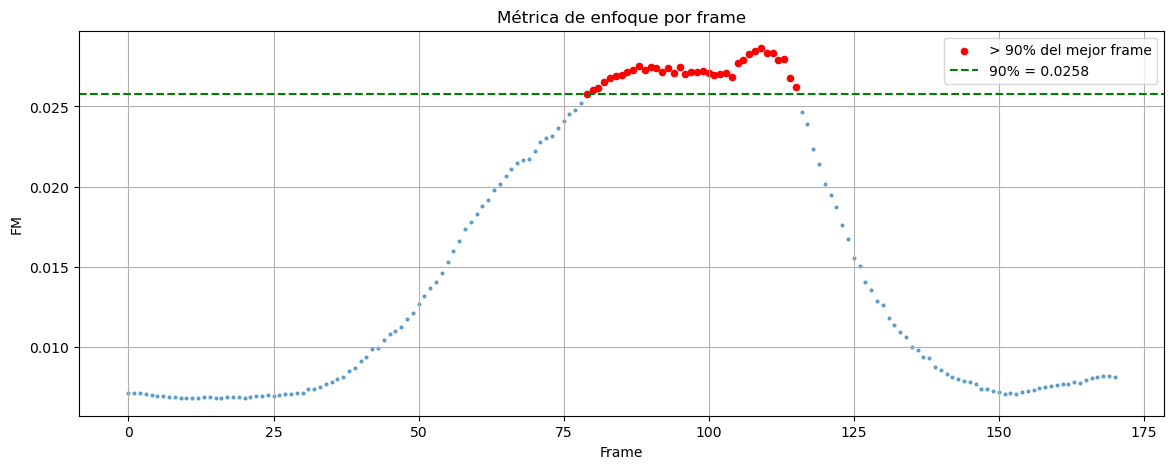

In [79]:
# Armamos la ruta del archivo
ruta_video = "videos/focus_video.mov"
print("Cargando video de la carpeta: " + str(ruta_video))

# Cargamos el video con opencv
captura_video = cv2.VideoCapture(ruta_video)

if not captura_video.isOpened():
        print("Error al abrir el archivo de video")
else:    
    num_frames = int(captura_video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"Cantidad de frames: {num_frames}")

    # procesamos todos los frames
    metricas = []

    # bandera utilizada para imprimir la resolución utilizada solo 1 vez
    primer_frame = True

    while True:
        ret, frame = captura_video.read()

        if not ret:
            break

        # se calcula la métrica del frame según nuestra implementación del algoritmo del paper 
        metricas.append(calc_metrica_enfoque(frame))
        
        # imprimimos el tamaño de la imágen 1 vez
        if primer_frame:
            alto, ancho = frame.shape[:2]
            print(f"Resolución: {ancho} x {alto}")
            primer_frame = False

    #pasamos de lista de Python a array de Numpy  
    metricas = np.array(metricas)

    # calculamos el umbral utilizado para definir "frame en foco"
    fm_max = metricas.max()
    umbral = 0.9 * fm_max

    frames_enfocados = np.where(metricas >= umbral)[0]

    print(f"FM máximo: {fm_max}")
    print(f"Umbral (90%): {umbral}")

    print("Frames enfocados:")
    print(frames_enfocados.tolist())

    plt.figure(figsize=(14, 5))

    x = np.arange(len(metricas))

    # Todos los frames
    plt.scatter(
        x,
        metricas,
        s=4,
        color="tab:blue",
        alpha=0.6
    )

    # Sólo los que superan el 90%
    plt.scatter(
        frames_enfocados,
        metricas[frames_enfocados],
        s=20,
        color="red",
        label="> 90% del mejor frame"
    )

    plt.axhline(
        umbral,
        color="green",
        linestyle="--",
        label=f"90% = {umbral:.4f}"
    )

    plt.xlabel("Frame")
    plt.ylabel("FM")
    plt.title("Métrica de enfoque por frame")
    plt.grid(True)
    plt.legend()

    plt.show()

Esto que viene fue generado por IA para que se vea lo que detecta el detector, hay que borrarlo:

In [80]:

ruta_video = "videos/focus_video.mov"
ruta_salida = "videos/focus_video_marcado.mp4"

# Convertir a set para búsquedas rápidas
frames_enfocados_set = set(frames_enfocados)

# Abrir video original
captura_video = cv2.VideoCapture(ruta_video)

if not captura_video.isOpened():
    raise ValueError(f"No se pudo abrir {ruta_video}")

# Propiedades del video
fps = captura_video.get(cv2.CAP_PROP_FPS)
ancho = int(captura_video.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(captura_video.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Crear video de salida
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_salida = cv2.VideoWriter(
    ruta_salida,
    fourcc,
    fps,
    (ancho, alto)
)

indice_frame = 0

while True:
    ret, frame = captura_video.read()

    if not ret:
        break

    if indice_frame in frames_enfocados_set:

        # Marco rojo
        cv2.rectangle(
            frame,
            (10, 10),
            (ancho - 10, alto - 10),
            (0, 0, 255),
            thickness=8
        )

        # Etiqueta
        cv2.putText(
            frame,
            f"ENFOCADO (frame {indice_frame})",
            (30, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 0, 255),
            2,
            cv2.LINE_AA
        )

    video_salida.write(frame)

    indice_frame += 1

captura_video.release()
video_salida.release()

print(f"Video guardado en: {ruta_salida}")

video_original = cv2.VideoCapture(ruta_video)
video_marcado = cv2.VideoCapture(ruta_salida)

if not video_original.isOpened():
    raise ValueError(f"No se pudo abrir el video original: {ruta_video}")

if not video_marcado.isOpened():
    raise ValueError(f"No se pudo abrir el video marcado: {ruta_salida}")

# Usamos los FPS del video original
fps_reproduccion = video_original.get(cv2.CAP_PROP_FPS)

if fps_reproduccion <= 0:
    fps_reproduccion = 30

# Tiempo entre frames, en milisegundos
retardo_ms = max(1, round(1000 / fps_reproduccion))

while True:
    ret_original, frame_original = video_original.read()
    ret_marcado, frame_marcado = video_marcado.read()

    # Terminar cuando alguno de los videos llegue al final
    if not ret_original or not ret_marcado:
        break

    # Asegurar que ambos frames tengan el mismo tamaño
    if frame_original.shape[:2] != frame_marcado.shape[:2]:
        frame_marcado = cv2.resize(
            frame_marcado,
            (
                frame_original.shape[1],  # ancho
                frame_original.shape[0]   # alto
            )
        )

    # Agregar títulos
    cv2.putText(
        frame_original,
        "Original",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    cv2.putText(
        frame_marcado,
        "Deteccion de enfoque",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    # Unir horizontalmente
    comparacion = cv2.hconcat([
        frame_original,
        frame_marcado
    ])

    cv2.imshow("Original vs deteccion de enfoque", comparacion)

    # Presionar Q para detener la reproducción
    tecla = cv2.waitKey(retardo_ms) & 0xFF

    if tecla == ord("q"):
        break

video_original.release()
video_marcado.release()
cv2.destroyAllWindows()

Video guardado en: videos/focus_video_marcado.mp4


Ahora definimos una región de interés cuadrada centrada en el frame de approx. 10 % del área del frame completo

In [81]:
def roi_central(frame, porcentaje_area=0.10):

    alto, ancho = frame.shape[:2]
    area_total = alto * ancho
    area_roi = area_total * porcentaje_area

    # ROI cuadrada
    lado = int(np.sqrt(area_roi))

    cx = ancho // 2
    cy = alto // 2

    x1 = max(0, cx - lado // 2)
    x2 = min(ancho, cx + lado // 2)

    y1 = max(0, cy - lado // 2)
    y2 = min(alto, cy + lado // 2)

    return frame[y1:y2, x1:x2]

Corremos el algoritmo con el ROI como fuente

Cargando video de la carpeta: videos/focus_video.mov
Cantidad de frames: 171
Resolución: 150 x 150
FM máximo: 0.3506222222222222
Umbral (90%): 0.31556
Frames enfocados:
[91, 93, 95, 97, 99, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113]


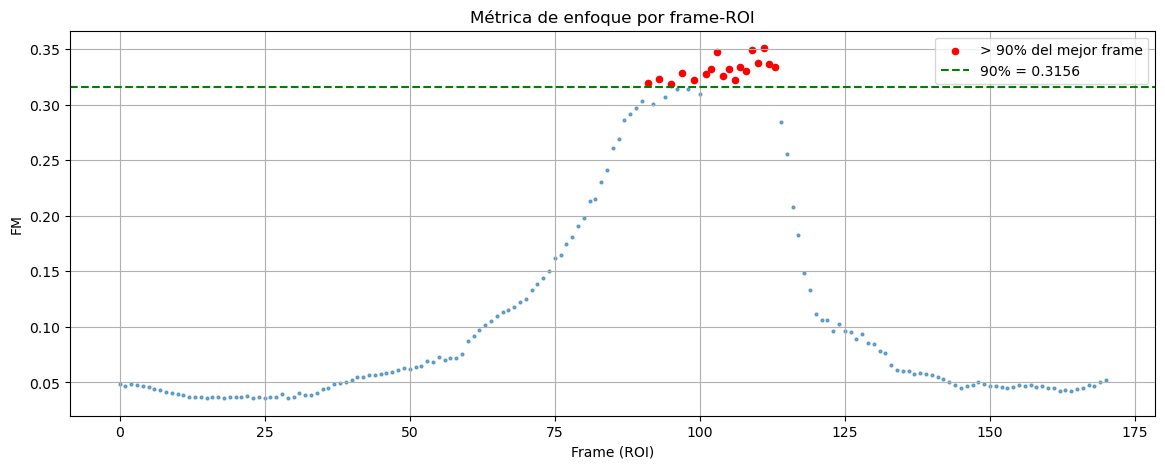

In [82]:
# Armamos la ruta del archivo
ruta_video = "videos/focus_video.mov"
print("Cargando video de la carpeta: " + str(ruta_video))

# Cargamos el video con opencv
captura_video = cv2.VideoCapture(ruta_video)

if not captura_video.isOpened():
        print("Error al abrir el archivo de video")
else:    
    num_frames = int(captura_video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"Cantidad de frames: {num_frames}")

    # procesamos todos los frames
    metricas_roi = []
    primer_frame = True

    while True:
        ret, frame = captura_video.read()

        if not ret:
            break

        roi = roi_central(frame, porcentaje_area=0.1)
        metricas_roi.append(calc_metrica_enfoque(roi))
        if primer_frame:
            alto, ancho = roi.shape[:2]
            print(f"Resolución: {ancho} x {alto}")
            primer_frame = False

    metricas_roi = np.array(metricas_roi)

    fm_max_roi = metricas_roi.max()
    umbral_roi = 0.9 * fm_max_roi

    frames_enfocados_roi = np.where(metricas_roi >= umbral_roi)[0]

    print(f"FM máximo: {fm_max_roi}")
    print(f"Umbral (90%): {umbral_roi}")

    print("Frames enfocados:")
    print(frames_enfocados_roi.tolist())

    plt.figure(figsize=(14, 5))

    x = np.arange(len(metricas_roi))

    # Todos los frames
    plt.scatter(
        x,
        metricas_roi,
        s=4,
        color="tab:blue",
        alpha=0.6
    )

    # Sólo los que superan el 90%
    plt.scatter(
        frames_enfocados_roi,
        metricas_roi[frames_enfocados_roi],
        s=20,
        color="red",
        label="> 90% del mejor frame"
    )

    plt.axhline(
        umbral_roi,
        color="green",
        linestyle="--",
        label=f"90% = {umbral_roi:.4f}"
    )

    plt.xlabel("Frame (ROI)")
    plt.ylabel("FM")
    plt.title("Métrica de enfoque por frame-ROI")
    plt.grid(True)
    plt.legend()

    plt.show()

In [83]:
comunes = np.intersect1d(
    frames_enfocados,
    frames_enfocados_roi
)

print(f"Coinciden en {len(comunes)} frames")
print(comunes)

frames_distintos = np.setxor1d(
    frames_enfocados,
    frames_enfocados_roi
)

print(f"Frames donde difieren: {len(frames_distintos)}")
print(frames_distintos)

Coinciden en 18 frames
[ 91  93  95  97  99 101 102 103 104 105 106 107 108 109 110 111 112 113]
Frames donde difieren: 19
[ 79  80  81  82  83  84  85  86  87  88  89  90  92  94  96  98 100 114
 115]


Observamos que al quedarnos con una región de interes en el medio de la imágen (ocupada completamente por el pedal de distorsión) la "imágen" a la cual le aplicamos el algoritmo cambia completamente, lo que hace que la métrica aumente mas de un órden de magnitud. No parece apropiado utilizar el mismo umbral en valor absoluto ya que se comparan cosas muy distintas. Utilizando el mismo criterio de clasificar como enfocados a aquellos ROI con métrica superior al 90 % de la máxima, 19 frames quedan afuera de la clase "ROI enfocado". 

Para explicar las diferencias entre frame completo y ROI nos enfocamos en por qué la métrica aumenta mas de 1 orden de magnitud al correrla sobre el ROI. Intuitivamente, el pedal debe tener la mayor parte de las componentes de alta frecuencia de la imágen ya que tiene el texto azul sobre el cuerpo negro, el pulsador metálico plateado que tiene cierto brillo y está rodeado por el cuerpo negro y algo similar pasa con el led. Los potenciómetros también contrastan contra el negro opaco del cuerpo. Todas éstas diferencias de contraste entre píxeles adyacentes de cada frame contribuyen a la magnitud de las componentes de alta frecuencia. 

Fuera del pedal, la mesa tiene una textura mucho mas suave con lo cual se espera que su aporte a la huella en la magnitud espectral de la imágen sea baja.

Si analizamos como se calcula la métrica, es posible que la componente de máxima magnitud (y por ende el umbral) esté dada por el detalle del pedal y sea similar en ambos casos. Como el ROI contiene gran parte del pedal, si la mesa no cuntribuye mucho al perfil de magnitudes de la FFT, entonces es posible que la cantidad de componentes de frecuencia que superan el umbral en ambos casos no sea tan distinta (bastante menor a un órden de magnitud). Ahora bien, en el último paso, el cálculo de la métrica normaliza por el tamaño de la imágen. En el caso de la imágen completa, el denominador es 640 x 360 = 230400 y en el caso del ROI 150 x 150 = 22500. O sea, hay un órden de magnitud de diferencia en el denominador de la normalización final con lo cual si el pedal en sí tiene mucha influencia en las magnitudes de cada componente del espectro, entonces ésto explica la diferencia en la métrica.

Si el razonamiento anterior es válido, es de esperarse que en el caso del ROI la métrica sea mucho mas sensible al desenfoque y por ello, usando el mismo criterio que en el caso del frame completo, 19 frames pierden la clasificación de "enfocados".

## Unsharp Masking

Para aplicar unsharp masking, primero seleccionamos los frames para los que vale la pena hacerlo ya que el proceso tiene sus limitaciones. El criterio es seleccionar aquellos con métrica mayor a 80 % del máximo y menor a 90 % (porque desde 90 % ya los consideramos enfocados)

In [84]:
fm_max = metricas.max()

umbral_80 = 0.80 * fm_max
umbral_90 = 0.90 * fm_max

frames_candidatos = np.where(
    (metricas >= umbral_80) &
    (metricas < umbral_90)
)[0]

print(frames_candidatos)

[ 72  73  74  75  76  77  78 116 117]


Luego, aplicamos el proceso de unsharp masking a los frames candidatos

In [85]:
k = 2.5

captura_video = cv2.VideoCapture(ruta_video)

metricas_mejoradas = metricas.copy()

indice = 0

while True:

    ret, frame = captura_video.read()

    if not ret:
        break

    if indice in frames_candidatos:

        gauss = cv2.GaussianBlur(
            frame,
            (7, 7),
            0.5
        )

        frame_sharp = cv2.addWeighted(
            frame,
            k + 1,
            gauss,
            -k,
            0
        )

        metricas_mejoradas[indice] = (
            calc_metrica_enfoque(frame_sharp)
        )

    indice += 1

captura_video.release()

Con los frames ya procesados, volvemos a calcular los enfocados y comparamos

In [86]:
frames_enfocados_nuevos = np.where(
    metricas_mejoradas >= umbral_90
)[0]

nuevos = np.setdiff1d(
    frames_enfocados_nuevos,
    frames_enfocados
)

print("Frames recuperados luego del sharpening:")
print(nuevos)

Frames recuperados luego del sharpening:
[ 73  74  75  76  77  78 116 117]


Repetimos el scatter plot de métrica vs número de frame comparando el video original (frame completo) con los frames modificados por el unsharp masking.

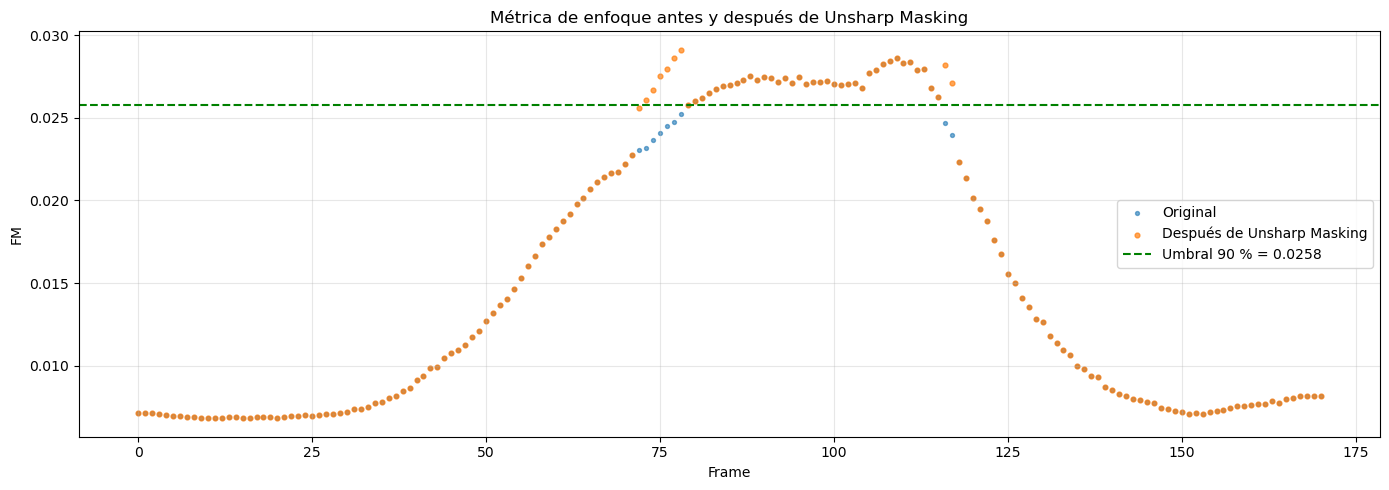

In [87]:
x = np.arange(len(metricas))

plt.figure(figsize=(14, 5))

# Métricas originales
plt.scatter(
    x,
    metricas,
    s=8,
    color="tab:blue",
    alpha=0.6,
    label="Original"
)

# Métricas después de aplicar Unsharp Masking
plt.scatter(
    x,
    metricas_mejoradas,
    s=12,
    color="tab:orange",
    alpha=0.7,
    label="Después de Unsharp Masking"
)

# Umbral del 90 %
plt.axhline(
    umbral_90,
    color="green",
    linestyle="--",
    label=f"Umbral 90 % = {umbral_90:.4f}"
)

plt.xlabel("Frame")
plt.ylabel("FM")
plt.title("Métrica de enfoque antes y después de Unsharp Masking")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Observamos que palicar el proceso unsharp masking (aplicar el filtro de suavizado, restar la imágen original con la suavizada para obtener componentes de alta frecuencia y sumar la máscara resultante a la imágen inicial) ayuda a recuperar 8 frames que según nuestro criterio estaban originalmente desenfocados. Sin embargo, con nuestra elección de umbral y parámetros, queda clara la limitación del filtro ya ue un frame de los seleccionados, no llega a estar enfocado (según el criterio impuesto) aún luego del proceso de unsharp masking.